# DataCo Supply Chain : analyse prédictive

Ce notebook produit les **résultats Python** qui alimenteront les pages *Prédictive* de notre dashboard Power BI.

| Partie | Question | Fichiers produit |
|---|---|---|
| **A. Prévision** | Quel revenu et combien de commandes dans les prochains mois ? | `Forecast.csv` |
| **B. Risque de retard** | Quelle est la probabilité qu'une commande soit livrée en retard ? | `Late_Risk.csv`, `Feature_Importance.csv`, `Model_Metrics.csv` |


NB: Les fichiers sont écrits dans le dossier `powerbi_outputs/`.

Les définitions sont alignées sur notre modèle Power BI : *Revenue* = somme de `Sales`, *Total Orders* = nombre de `Order Id` distincts, commande *en retard* = délai réel supérieur au délai prévu, commandes « Shipping canceled » exclues du taux de retard.

In [1]:
# Installation des bibliothèques nessécaires
# %pip install -q pandas numpy scikit-learn statsmodels matplotlib

## 0. Configuration

In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", FutureWarning)

# ---- Réglages ----
DATA_PATH = "DataCoSupplyChainDataset.csv"   # fichier source
OUTPUT_DIR = "powerbi_outputs"               # dossier des CSV pour Power BI
HORIZON = 6             # nombre de mois à prévoir après la dernière donnée
BACKTEST_MONTHS = 6     # mois mis de côté pour comparer les modèles de prévision
SPARSE_RATIO = 0.5      # un mois final avec moins de 50 % de la médiane des commandes est jugé incomplet
TEST_SHARE = 0.20       # part des commandes les plus récentes gardée pour tester le modèle de retard
RISK_LOW, RISK_HIGH = 0.45, 0.70   # seuils des niveaux de risque : Low < 0.45 <= Medium < 0.70 <= High
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Couleurs et style des graphiques
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e3e2de", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "legend.frameon": False,
})
fmt_int = lambda x: f"{x:,.0f}".replace(",", " ")
fmt_millions = FuncFormatter(lambda v, _: f"${v / 1e6:.1f}M")

## 1. Chargement et contrôle des données

Le fichier DataCo est encodé en **Windows-1252** (pas en UTF-8) et ses dates sont au format **mois/jour/année**. Le notebook gère les deux.

In [3]:
USE_COLS = [
    "Order Id", "Order Item Id", "order date (DateOrders)", "Sales",
    "Days for shipping (real)", "Days for shipment (scheduled)", "Delivery Status", "Late_delivery_risk",
    "Shipping Mode", "Market", "Order Region", "Category Name", "Department Name",
    "Customer Segment", "Type", "Order Item Quantity", "Order Item Discount Rate", "Order Item Product Price",
]


def read_dataco(path):
    header = pd.read_csv(path, nrows=0, encoding="latin-1").columns
    missing = [c for c in USE_COLS if c not in header]
    if missing:
        raise ValueError(f"Colonnes introuvables dans le fichier : {missing}")
    for enc in ("cp1252", "latin-1"):
        try:
            return pd.read_csv(path, usecols=USE_COLS, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError("Impossible de lire le fichier avec cp1252 ni latin-1")


df = read_dataco(DATA_PATH)

# Dates : mois/jour/année ; on essaie jour/mois/année si rien ne passe
raw_dates = df["order date (DateOrders)"]
df["Order Date"] = pd.to_datetime(raw_dates, format="%m/%d/%Y %H:%M", errors="coerce")
if df["Order Date"].isna().all():
    df["Order Date"] = pd.to_datetime(raw_dates, format="%d/%m/%Y %H:%M", errors="coerce")
if df["Order Date"].isna().any():
    print(f"Attention : {df['Order Date'].isna().sum()} dates non lues, ces lignes sont retirées.")
    df = df.dropna(subset=["Order Date"])

not_canceled = df["Delivery Status"] != "Shipping canceled"
late_rate = (df.loc[not_canceled, "Days for shipping (real)"] > df.loc[not_canceled, "Days for shipment (scheduled)"]).mean()

print("Contrôle : ces valeurs doivent correspondre à notre Power BI")
print(f"  Lignes de commande : {fmt_int(len(df))}")
print(f"  Total Orders       : {fmt_int(df['Order Id'].nunique())}   (Power BI : 65 752)")
print(f"  Revenue            : {fmt_int(df['Sales'].sum())} $  (Power BI : 36 784 735 $)")
print(f"  Late Delivery %    : {late_rate:.1%}   (Power BI : 57,3 %)")
print(f"  Période            : {df['Order Date'].min():%Y-%m-%d} -> {df['Order Date'].max():%Y-%m-%d}")

Contrôle : ces valeurs doivent correspondre à notre Power BI
  Lignes de commande : 180 519
  Total Orders       : 65 752   (Power BI : 65 752)
  Revenue            : 36 784 735 $  (Power BI : 36 784 735 $)
  Late Delivery %    : 57.3%   (Power BI : 57,3 %)
  Période            : 2015-01-01 -> 2018-01-31


---
# Partie A. Prévision du revenu et des commandes

## A1. Série mensuelle

On regroupe par mois de commande. Un mois **final incomplet** (peu de commandes, ou dernier jour du mois non atteint) fausserait la prévision : il est détecté puis exclu de l'entraînement, mais reste visible dans les graphiques.

In [4]:
df["Order Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
monthly = (df.groupby("Order Month")
             .agg(Revenue=("Sales", "sum"), Orders=("Order Id", "nunique"))
             .asfreq("MS"))
if monthly.isna().any().any():
    print("Mois sans commande : remplacés par 0 ->", list(monthly[monthly["Orders"].isna()].index.strftime("%Y-%m")))
    monthly = monthly.fillna(0)

# Détection des mois finaux incomplets
median_orders = monthly["Orders"].median()
n_excluded = 0
while n_excluded < len(monthly) - 24 and monthly["Orders"].iloc[-1 - n_excluded] < SPARSE_RATIO * median_orders:
    n_excluded += 1
last_date = df["Order Date"].max()
if n_excluded == 0 and last_date.day < last_date.days_in_month - 1:
    n_excluded = 1   # dernier mois coupé avant sa fin

train = monthly.iloc[: len(monthly) - n_excluded]
excluded = monthly.iloc[len(monthly) - n_excluded:]

print(f"Mois dans la série : {len(monthly)} ({monthly.index[0]:%Y-%m} -> {monthly.index[-1]:%Y-%m})")
print(f"Médiane des commandes par mois : {fmt_int(median_orders)}")
if n_excluded:
    print(f"Mois exclus de l'entraînement ({n_excluded}) : {list(excluded.index.strftime('%Y-%m'))}")
    print("-> à vérifier : si ces mois sont réels et non incomplets, mets SPARSE_RATIO = 0 plus haut.")
else:
    print("Aucun mois incomplet détecté.")
display(monthly.tail(8).assign(Revenue=lambda d: d["Revenue"].round(0)))

Mois dans la série : 37 (2015-01 -> 2018-01)
Médiane des commandes par mois : 1 763
Aucun mois incomplet détecté.


,Revenue,Orders
Order Month,,
2017-06-01,1032086.0,1676
2017-07-01,1104373.0,1776
2017-08-01,1109337.0,1768
2017-09-01,1143775.0,1723
2017-10-01,1073994.0,2101
2017-11-01,626914.0,2055
2017-12-01,503911.0,2124
2018-01-01,331650.0,2123


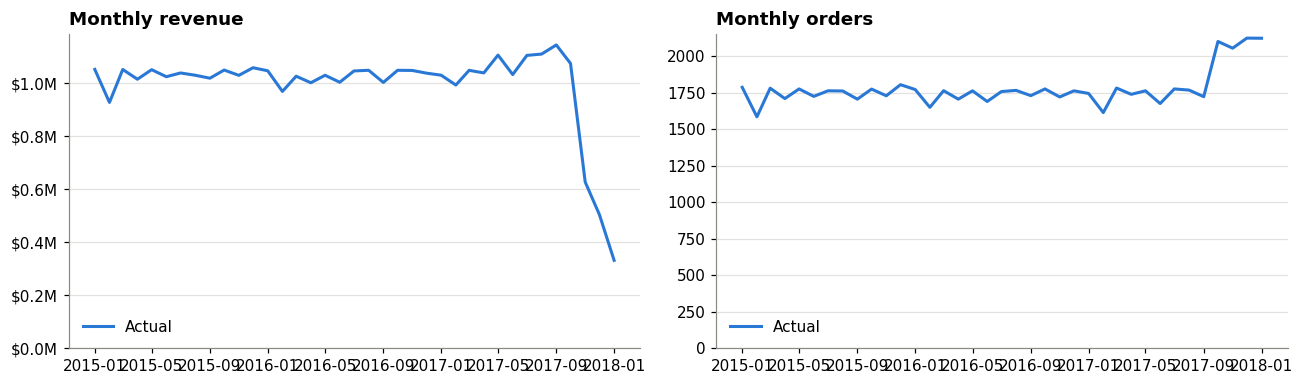

In [5]:
def plot_history(ax, col, title):
    ax.plot(train.index, train[col], color=BLUE, lw=2, label="Actual")
    if n_excluded:
        ax.plot(excluded.index, excluded[col], color=ORANGE, lw=2, marker="o", ms=6, label="Excluded (incomplete)")
        ax.plot([train.index[-1], excluded.index[0]], [train[col].iloc[-1], excluded[col].iloc[0]], color=ORANGE, lw=2)
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.legend(loc="lower left")


fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_history(axes[0], "Revenue", "Monthly revenue")
axes[0].yaxis.set_major_formatter(fmt_millions)
plot_history(axes[1], "Orders", "Monthly orders")
plt.tight_layout()
plt.show()

## A2. Comparaison de modèles (backtest)

Quatre méthodes sont testées sur les `BACKTEST_MONTHS` derniers mois d'entraînement, que le modèle n'a pas vus. On garde, pour chaque indicateur, celle qui a l'erreur moyenne (MAPE) la plus faible.

- **Seasonal naive** : répète la valeur du même mois l'année précédente (point de comparaison simple).
- **ETS** : lissage exponentiel (tendance amortie et/ou saisonnalité annuelle).

Avec 3 ans de données et 6 mois de test, le classement reste **indicatif** : un écart de quelques points de MAPE n'est pas significatif.

In [6]:
from statsmodels.tsa.exponential_smoothing.ets import ETSModel


def future_index(last_month, h):
    return pd.date_range(last_month + pd.offsets.MonthBegin(1), periods=h, freq="MS")


def seasonal_naive(y, h):
    idx = future_index(y.index[-1], h)
    mean = np.array([y.iloc[-12 + (i % 12)] for i in range(h)])
    sd = y.diff(12).dropna().std()
    return pd.DataFrame({"mean": mean, "lower": mean - 1.28 * sd, "upper": mean + 1.28 * sd}, index=idx)


def ets_forecast(y, h, trend=None, damped=False, seasonal=None):
    model = ETSModel(y, error="add", trend=trend, damped_trend=damped,
                     seasonal=seasonal, seasonal_periods=12 if seasonal else None)
    res = model.fit(disp=False, maxiter=2000)
    sf = res.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.2)   # intervalle à 80 %
    return pd.DataFrame({"mean": sf["mean"].values, "lower": sf["pi_lower"].values,
                         "upper": sf["pi_upper"].values}, index=future_index(y.index[-1], h))


CANDIDATES = {
    "Seasonal naive": lambda y, h: seasonal_naive(y, h),
    "ETS damped trend": lambda y, h: ets_forecast(y, h, trend="add", damped=True),
    "ETS damped trend + seasonality": lambda y, h: ets_forecast(y, h, trend="add", damped=True, seasonal="add"),
    "ETS seasonality only": lambda y, h: ets_forecast(y, h, seasonal="add"),
}

mape = lambda actual, pred: float(np.mean(np.abs((actual - pred) / actual)) * 100)

rows = []
for metric in ["Revenue", "Orders"]:
    y_all = train[metric]
    y_fit, y_test = y_all.iloc[:-BACKTEST_MONTHS], y_all.iloc[-BACKTEST_MONTHS:]
    for name, fn in CANDIDATES.items():
        if len(y_fit) < 24:
            continue   # pas assez d'historique pour estimer la saisonnalité
        try:
            pred = fn(y_fit, BACKTEST_MONTHS)["mean"].values
            rows.append({"Metric": metric, "Model": name, "MAPE %": round(mape(y_test.values, pred), 1)})
        except Exception as exc:
            print(f"  {metric} / {name} ignoré : {exc}")

backtest = pd.DataFrame(rows)
display(backtest.pivot(index="Model", columns="Metric", values="MAPE %"))

best_model = backtest.loc[backtest.groupby("Metric")["MAPE %"].idxmin()].set_index("Metric")["Model"].to_dict()
print("Modèle retenu :", best_model)

Metric,Orders,Revenue
Model,,
ETS damped trend,11.8,67.7
ETS damped trend + seasonality,11.0,68.0
ETS seasonality only,10.8,68.0
Seasonal naive,11.2,67.3


Modèle retenu : {'Orders': 'ETS seasonality only', 'Revenue': 'Seasonal naive'}


## A3. Prévision finale

Le modèle retenu est réentraîné sur **tous** les mois valides. La prévision commence juste après le dernier mois valide : si des mois incomplets ont été exclus, elle les couvre aussi, ce qui permet de comparer la prévision à ce qui a été réellement observé.

In [7]:
h = n_excluded + HORIZON
forecasts = {}
for metric in ["Revenue", "Orders"]:
    forecasts[metric] = CANDIDATES[best_model[metric]](train[metric], h)

# Table finale pour Power BI : une ligne par mois
idx = monthly.index.union(forecasts["Revenue"].index)
out = pd.DataFrame(index=idx)
out["Status"] = "Forecast"
out.loc[train.index, "Status"] = "Actual"
if n_excluded:
    out.loc[excluded.index, "Status"] = "Incomplete data (excluded)"
for metric in ["Revenue", "Orders"]:
    out[f"{metric}_Actual"] = monthly[metric]
    out[f"{metric}_Forecast"] = forecasts[metric]["mean"]
    out[f"{metric}_Lower"] = forecasts[metric]["lower"].clip(lower=0)
    out[f"{metric}_Upper"] = forecasts[metric]["upper"]
    out[f"Model_{metric}"] = best_model[metric]
out.index.name = "Month"
forecast_table = out.reset_index()[[
    "Month", "Status", "Revenue_Actual", "Revenue_Forecast", "Revenue_Lower", "Revenue_Upper",
    "Orders_Actual", "Orders_Forecast", "Orders_Lower", "Orders_Upper", "Model_Revenue", "Model_Orders"]]
forecast_table["Month"] = forecast_table["Month"].dt.strftime("%Y-%m-%d")
for c in forecast_table.columns:
    if c.startswith(("Revenue_", "Orders_")):
        forecast_table[c] = forecast_table[c].round(2)

forecast_table.to_csv(f"{OUTPUT_DIR}/Forecast.csv", index=False, encoding="utf-8")
display(forecast_table.tail(h + 2))

,Month,Status,Revenue_Actual,Revenue_Forecast,Revenue_Lower,Revenue_Upper,Orders_Actual,Orders_Forecast,Orders_Lower,Orders_Upper,Model_Revenue,Model_Orders
35,2017-12-01,Actual,503910.82,NaN,NaN,NaN,2124.0,NaN,NaN,NaN,Seasonal naive,ETS seasonality only
36,2018-01-01,Actual,331650.12,NaN,NaN,NaN,2123.0,NaN,NaN,NaN,Seasonal naive,ETS seasonality only
37,2018-02-01,Forecast,NaN,992534.90,740517.41,1244552.39,NaN,1961.73,1900.42,2023.05,Seasonal naive,ETS seasonality only
38,2018-03-01,Forecast,NaN,1048004.78,795987.29,1300022.27,NaN,2111.95,2025.48,2198.42,Seasonal naive,ETS seasonality only
39,2018-04-01,Forecast,NaN,1038321.62,786304.13,1290339.11,NaN,2045.47,1939.65,2151.28,Seasonal naive,ETS seasonality only
40,2018-05-01,Forecast,NaN,1105485.32,853467.83,1357502.81,NaN,2085.16,1963.03,2207.28,Seasonal naive,ETS seasonality only
41,2018-06-01,Forecast,NaN,1032086.49,780069.00,1284103.98,NaN,2005.63,1869.12,2142.13,Seasonal naive,ETS seasonality only
42,2018-07-01,Forecast,NaN,1104373.36,852355.87,1356390.85,NaN,2065.04,1915.53,2214.54,Seasonal naive,ETS seasonality only


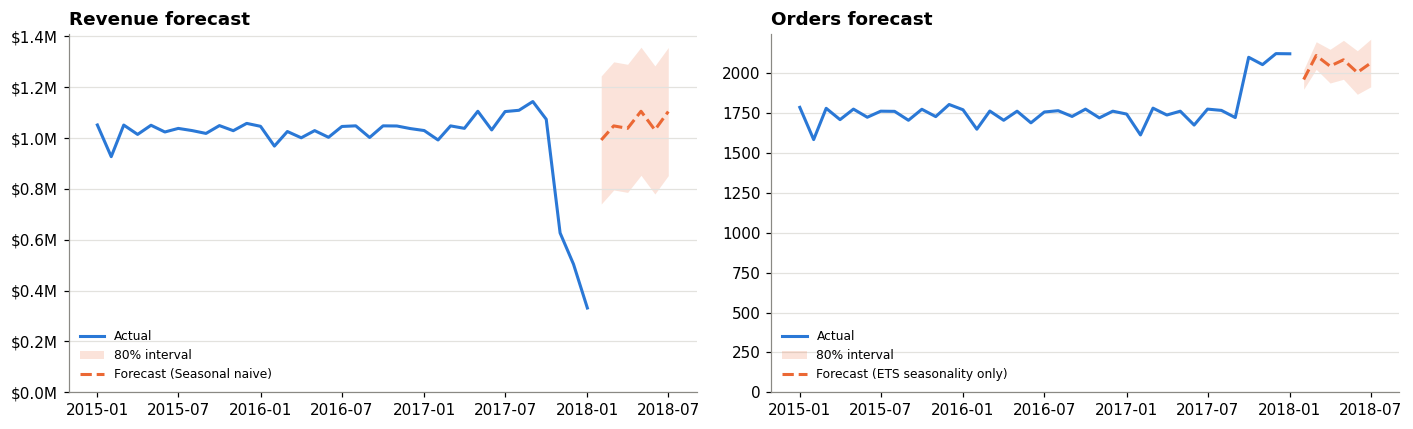

In [8]:
def plot_forecast(ax, metric, title):
    f = forecasts[metric]
    ax.plot(train.index, train[metric], color=BLUE, lw=2, label="Actual")
    if n_excluded:
        ax.plot(excluded.index, excluded[metric], color=GRAY, lw=2, marker="o", ms=5, label="Observed, excluded from model")
    ax.fill_between(f.index, f["lower"].clip(lower=0), f["upper"], color=ORANGE, alpha=0.18, lw=0, label="80% interval")
    ax.plot(f.index, f["mean"], color=ORANGE, lw=2, ls="--", label=f"Forecast ({best_model[metric]})")
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.legend(loc="lower left", fontsize=8)


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_forecast(axes[0], "Revenue", "Revenue forecast")
axes[0].yaxis.set_major_formatter(fmt_millions)
plot_forecast(axes[1], "Orders", "Orders forecast")
plt.tight_layout()
plt.show()

---
# Partie B. Risque de retard de livraison

## B1. Préparation : éviter la fuite de données

Le modèle doit prédire le retard **au moment de la commande**. Il n'utilise donc que des informations connues à cet instant :

| Utilisées | Volontairement exclues (elles « donnent la réponse ») |
|---|---|
| mode d'expédition, délai prévu, marché, région, catégorie, département, segment client, type de paiement, quantité, remise, prix, mois / jour / heure de commande | `Days for shipping (real)`, `Delivery Status`, `Late_delivery_risk`, date d'expédition, `Order Status` |

La variable à prédire est `Late` : **1** si le délai réel dépasse le délai prévu. Les commandes « Shipping canceled » sont exclues, comme dans nos mesure DAX.

In [9]:
m = df[df["Delivery Status"] != "Shipping canceled"].copy().reset_index(drop=True)
m["Late"] = (m["Days for shipping (real)"] > m["Days for shipment (scheduled)"]).astype(int)

agree = (m["Late"] == m["Late_delivery_risk"]).mean()
print(f"Accord entre notre définition du retard et Late_delivery_risk : {agree:.1%}")
print(f"Part de commandes en retard : {m['Late'].mean():.1%}   ({fmt_int(len(m))} lignes)")

m["Order Month Number"] = m["Order Date"].dt.month
m["Order Day of Week"] = m["Order Date"].dt.dayofweek
m["Order Hour"] = m["Order Date"].dt.hour

CAT = ["Shipping Mode", "Market", "Order Region", "Category Name", "Department Name", "Customer Segment", "Type"]
NUM = ["Days for shipment (scheduled)", "Order Item Quantity", "Order Item Discount Rate",
       "Order Item Product Price", "Order Month Number", "Order Day of Week", "Order Hour"]
FEATURES = CAT + NUM
X, y = m[FEATURES], m["Late"]

# Découpage chronologique : on entraîne sur le passé, on teste sur les commandes les plus récentes
cutoff = m["Order Date"].quantile(1 - TEST_SHARE)
is_train = m["Order Date"] < cutoff
X_train, y_train, X_test, y_test = X[is_train], y[is_train], X[~is_train], y[~is_train]
print(f"Entraînement : {fmt_int(len(X_train))} lignes (avant {cutoff:%Y-%m-%d})   |   Test : {fmt_int(len(X_test))} lignes")

Accord entre notre définition du retard et Late_delivery_risk : 100.0%
Part de commandes en retard : 57.3%   (172 765 lignes)
Entraînement : 138 211 lignes (avant 2017-04-22)   |   Test : 34 554 lignes


## B2. Modèle et comparaison avec des références simples

Le modèle (*gradient boosting*) est comparé à deux références :
1. **Toujours prédire la classe la plus fréquente.**
2. **Règle simple par mode d'expédition** : la probabilité de retard est le taux observé pour ce mode dans les données d'entraînement.

Si le modèle ne fait pas mieux que la règle par mode d'expédition, c'est une information utile : les autres variables n'apportent alors rien.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder


def make_model():
    pre = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT),
        ("num", "passthrough", NUM),
    ])
    clf = HistGradientBoostingClassifier(
        categorical_features=[True] * len(CAT) + [False] * len(NUM),
        max_iter=300, learning_rate=0.05, early_stopping=True,
        validation_fraction=0.1, n_iter_no_change=20, random_state=RANDOM_STATE)
    return Pipeline([("pre", pre), ("clf", clf)])


model = make_model().fit(X_train, y_train)
p_model = model.predict_proba(X_test)[:, 1]

# Références
majority = int(y_train.mean() >= 0.5)
mode_rate = y_train.groupby(X_train["Shipping Mode"]).mean()
p_rule = X_test["Shipping Mode"].map(mode_rate).fillna(y_train.mean()).values


def scores(name, proba, pred):
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "ROC AUC": roc_auc_score(y_test, proba),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0)}


metrics = pd.DataFrame([
    scores("Always predict majority class", np.full(len(y_test), 0.5), np.full(len(y_test), majority)),
    scores("Rule: shipping mode only", p_rule, (p_rule >= 0.5).astype(int)),
    scores("Gradient boosting (all order-time features)", p_model, (p_model >= 0.5).astype(int)),
]).round(3)
display(metrics)

print("Matrice de confusion du modèle (lignes = réel, colonnes = prédit ; 0 = à l'heure, 1 = en retard)")
display(pd.DataFrame(confusion_matrix(y_test, (p_model >= 0.5).astype(int)),
                     index=["Actual on time", "Actual late"], columns=["Pred. on time", "Pred. late"]))

metrics.to_csv(f"{OUTPUT_DIR}/Model_Metrics.csv", index=False, encoding="utf-8")

,Model,Accuracy,ROC AUC,Precision,Recall,F1
0,Always predict majority class,0.573,0.500,0.573,1.000,0.728
1,Rule: shipping mode only,0.696,0.744,0.887,0.538,0.670
2,Gradient boosting (all order-time features),0.723,0.778,0.889,0.591,0.710


Matrice de confusion du modèle (lignes = réel, colonnes = prédit ; 0 = à l'heure, 1 = en retard)


,Pred. on time,Pred. late
Actual on time,13292,1467
Actual late,8089,11706


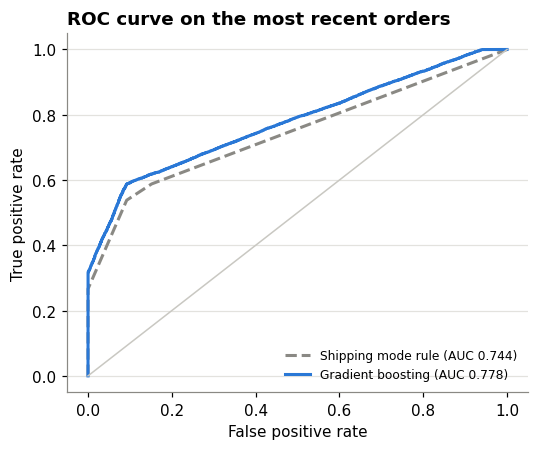

In [11]:
fig, ax = plt.subplots(figsize=(5, 4.2))
for name, proba, color, ls in [("Shipping mode rule", p_rule, GRAY, "--"), ("Gradient boosting", p_model, BLUE, "-")]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=color, lw=2, ls=ls, label=f"{name} (AUC {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], color="#c9c8c2", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curve on the most recent orders")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## B3. Quelles variables comptent ?

*Importance par permutation* : on mélange une variable à la fois sur les données de test et on mesure la **baisse d'AUC**. Plus la baisse est grande, plus le modèle dépend de cette variable.

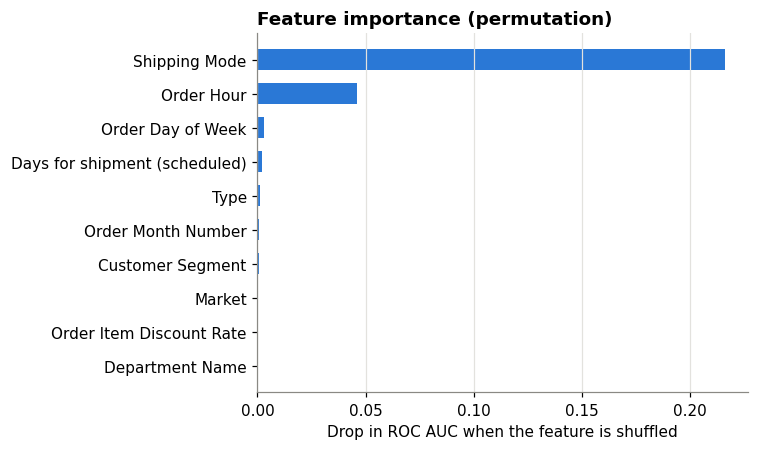

,Feature,AUC_Drop,AUC_Drop_Std
0,Shipping Mode,0.2160,0.0041
1,Order Hour,0.0460,0.0015
2,Order Day of Week,0.0028,0.0006
3,Days for shipment (scheduled),0.0022,0.0016
4,Type,0.0014,0.0011
5,Order Month Number,0.0007,0.0005
6,Customer Segment,0.0005,0.0009
7,Market,0.0002,0.0001
8,Order Item Discount Rate,0.0002,0.0006
9,Department Name,0.0001,0.0001


In [15]:
from sklearn.inspection import permutation_importance

sample = X_test.sample(min(20000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(model, sample, y_test.loc[sample.index], scoring="roc_auc",
                              n_repeats=3, random_state=RANDOM_STATE)
importance = (pd.DataFrame({"Feature": FEATURES, "AUC_Drop": perm.importances_mean, "AUC_Drop_Std": perm.importances_std})
                .sort_values("AUC_Drop", ascending=False).reset_index(drop=True).round(4))
importance.to_csv(f"{OUTPUT_DIR}/Feature_Importance.csv", index=False, encoding="utf-8")

fig, ax = plt.subplots(figsize=(7, 4.2))
top = importance.head(10).iloc[::-1]
ax.barh(top["Feature"], top["AUC_Drop"], color=BLUE, height=0.6)
ax.set_xlabel("Drop in ROC AUC when the feature is shuffled")
ax.set_title("Feature importance (permutation)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
plt.tight_layout()
plt.show()
display(importance.head(10))

## B4. Probabilité de retard pour chaque commande

Pour Power BI, il faut une probabilité pour **chaque ligne**. Pour qu'aucune probabilité ne vienne d'un modèle qui a vu la ligne, on utilise une validation croisée **par commande** (`Order Id`) : chaque ligne est notée par un modèle qui ne l'a pas vue, et les lignes d'une même commande restent ensemble.

Ces probabilités servent à **décrire le risque** (par mode, région, catégorie...). La performance du modèle se juge avec le test chronologique ci-dessus.

In [ ]:
from sklearn.model_selection import GroupKFold

oof = np.zeros(len(m))
for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, groups=m["Order Id"]), start=1):
    fold_model = make_model().fit(X.iloc[tr], y.iloc[tr])
    oof[te] = fold_model.predict_proba(X.iloc[te])[:, 1]
    print(f"  pli {fold}/5 terminé")
print(f"AUC hors échantillon (validation croisée) : {roc_auc_score(y, oof):.3f}")

risk = pd.DataFrame({
    "Order Item Id": m["Order Item Id"],
    "Order Id": m["Order Id"],
    "Order Date": m["Order Date"].dt.strftime("%Y-%m-%d"),
    "Shipping Mode": m["Shipping Mode"],
    "Late_Risk_Probability": oof.round(4),
    "Actual_Late": m["Late"],
})
risk["Risk_Band"] = pd.cut(risk["Late_Risk_Probability"], bins=[-0.01, RISK_LOW, RISK_HIGH, 1.01],
                           labels=["Low", "Medium", "High"], right=False)
risk.to_csv(f"{OUTPUT_DIR}/Late_Risk.csv", index=False, encoding="utf-8")

# Contrôle : les probabilités moyennes doivent coller aux taux de retard réels
check = (risk.groupby("Shipping Mode")
             .agg(Orders=("Order Item Id", "count"), Avg_Predicted=("Late_Risk_Probability", "mean"),
                  Actual_Late_Rate=("Actual_Late", "mean")).round(3))
display(check)
band = (risk.groupby("Risk_Band", observed=True)
            .agg(Orders=("Order Item Id", "count"), Actual_Late_Rate=("Actual_Late", "mean")).round(3))
display(band)

  pli 1/5 terminé
  pli 2/5 terminé
  pli 3/5 terminé
  pli 4/5 terminé
  pli 5/5 terminé
AUC hors échantillon (validation croisée) : 0.771


,Orders,Avg_Predicted,Actual_Late_Rate
Shipping Mode,,,
First Class,26513,1.000,1.000
Same Day,9293,0.480,0.479
Second Class,33806,0.798,0.798
Standard Class,103153,0.398,0.398


,Orders,Actual_Late_Rate
Risk_Band,,
Low,96732,0.381
Medium,11978,0.396
High,64055,0.896


---
## Fichiers produits

In [ ]:
for name in sorted(os.listdir(OUTPUT_DIR)):
    path = os.path.join(OUTPUT_DIR, name)
    print(f"{name:26s} {os.path.getsize(path) / 1024:>9,.0f} Ko")
print(f"\nDossier : {os.path.abspath(OUTPUT_DIR)}")

Feature_Importance.csv             0 Ko
Forecast.csv                       4 Ko
Late_Risk.csv                  8,642 Ko
Model_Metrics.csv                  0 Ko

Dossier : c:\MANGAS\Projet Data Analysis\Projet2\powerbi_outputs
